# Checks of the DM-nucleus scattering rates
Comparisons for the users interested in the choices behind the defaults of RAPIDD (the rates themselves are
introduced in [evaluate_NR_rates.ipynb](evaluate_NR_rates.ipynb)):
1. nuclear models: GCN5082 (default), Fitzpatrick et al. (DMFormFactor), SN100PN;
2. annual modulation: time average of the modulated spectra vs the annual-average halo (elastic and inelastic DM);
3. XENONnT limits and wimprates: the XENONnT limits (and the LZ limits used by MadDM) are computed with the
   spectra of [wimprates](https://github.com/JelleAalbers/wimprates) (Helm form factor for SI, the structure
   functions of Klos et al. with two-body currents for SD). Comparing RAPIDD with wimprates, with the same halo,
   quantifies how well a RAPIDD cross section can be compared with those limits.

## 1. Nuclear models
The nuclear responses implemented in RAPIDD are:
  - Fitz: evaluated using DMFormFactorV6 ([Fitzpatrick et al.](https://www.ocf.berkeley.edu/~nanand/software/dmformfactor/))
  - GCN: evaluated using DMFormFactorV6 using the one-body density matrices (OBDM) computed employing a GCN5082 nuclear shell model. The OBDM were taken from [this repository](https://github.com/Berkeley-Electroweak-Physics/Elastic/tree/main).
  - SN: evaluated with the SN100PN nuclear shell model, taken from this [supplementary material article](https://journals.aps.org/prd/supplemental/10.1103/PhysRevD.109.075036/Supplementary.pdf).

In [1]:
import numpy as np
import rapidd
import matplotlib.pyplot as plt

In [2]:
# Global variables
target = 'Xe'  # Target element
nuclear_models = ['iso_Fitz', 'iso_GCN5082', 'pn_SN100PN']
m_chi = 200  # GeV, WIMP mass
rhoDM = 0.3  # GeV/cm^3, local DM density
nE = 100 # number of energy points
E_min = 0.1 # keV, minimum recoil energy
E_max = 100 # keV, maximum recoil energy
energies_NREFT = np.logspace(np.log10(E_min), np.log10(E_max), nE)

# Couplings to nucleons. Dimensionless as they are normalized to the higgs vev^2.
c_prot = 1.0 # coupling to protons
c_neut = 1.0 # coupling to neutrons

# NREFT operators from O_1 to O_15, excluding O_2
NREFT_coeffs_list = [i for i in range(1, 16) if i != 2]

In [3]:
NREFT_rates = {}
rapidd.read_halo('../lib/halo_table/halo_table_SHM.dat')

for i in NREFT_coeffs_list:
    NREFT_rates[i] = {}
    rapidd.reset_coefficients()
    rapidd.set_any_Ncoeff(c_prot, i, 'p')
    rapidd.set_any_Ncoeff(c_neut, i, 'n')
    for nucl_mod in nuclear_models:
        NREFT_rates[i][nucl_mod] = np.array([
                            rapidd.difrate_dER(
                            rhoDM=rhoDM, mDM=m_chi, ER=E,
                            model='SHM', target=target, basis=nucl_mod)
                            for E in energies_NREFT])

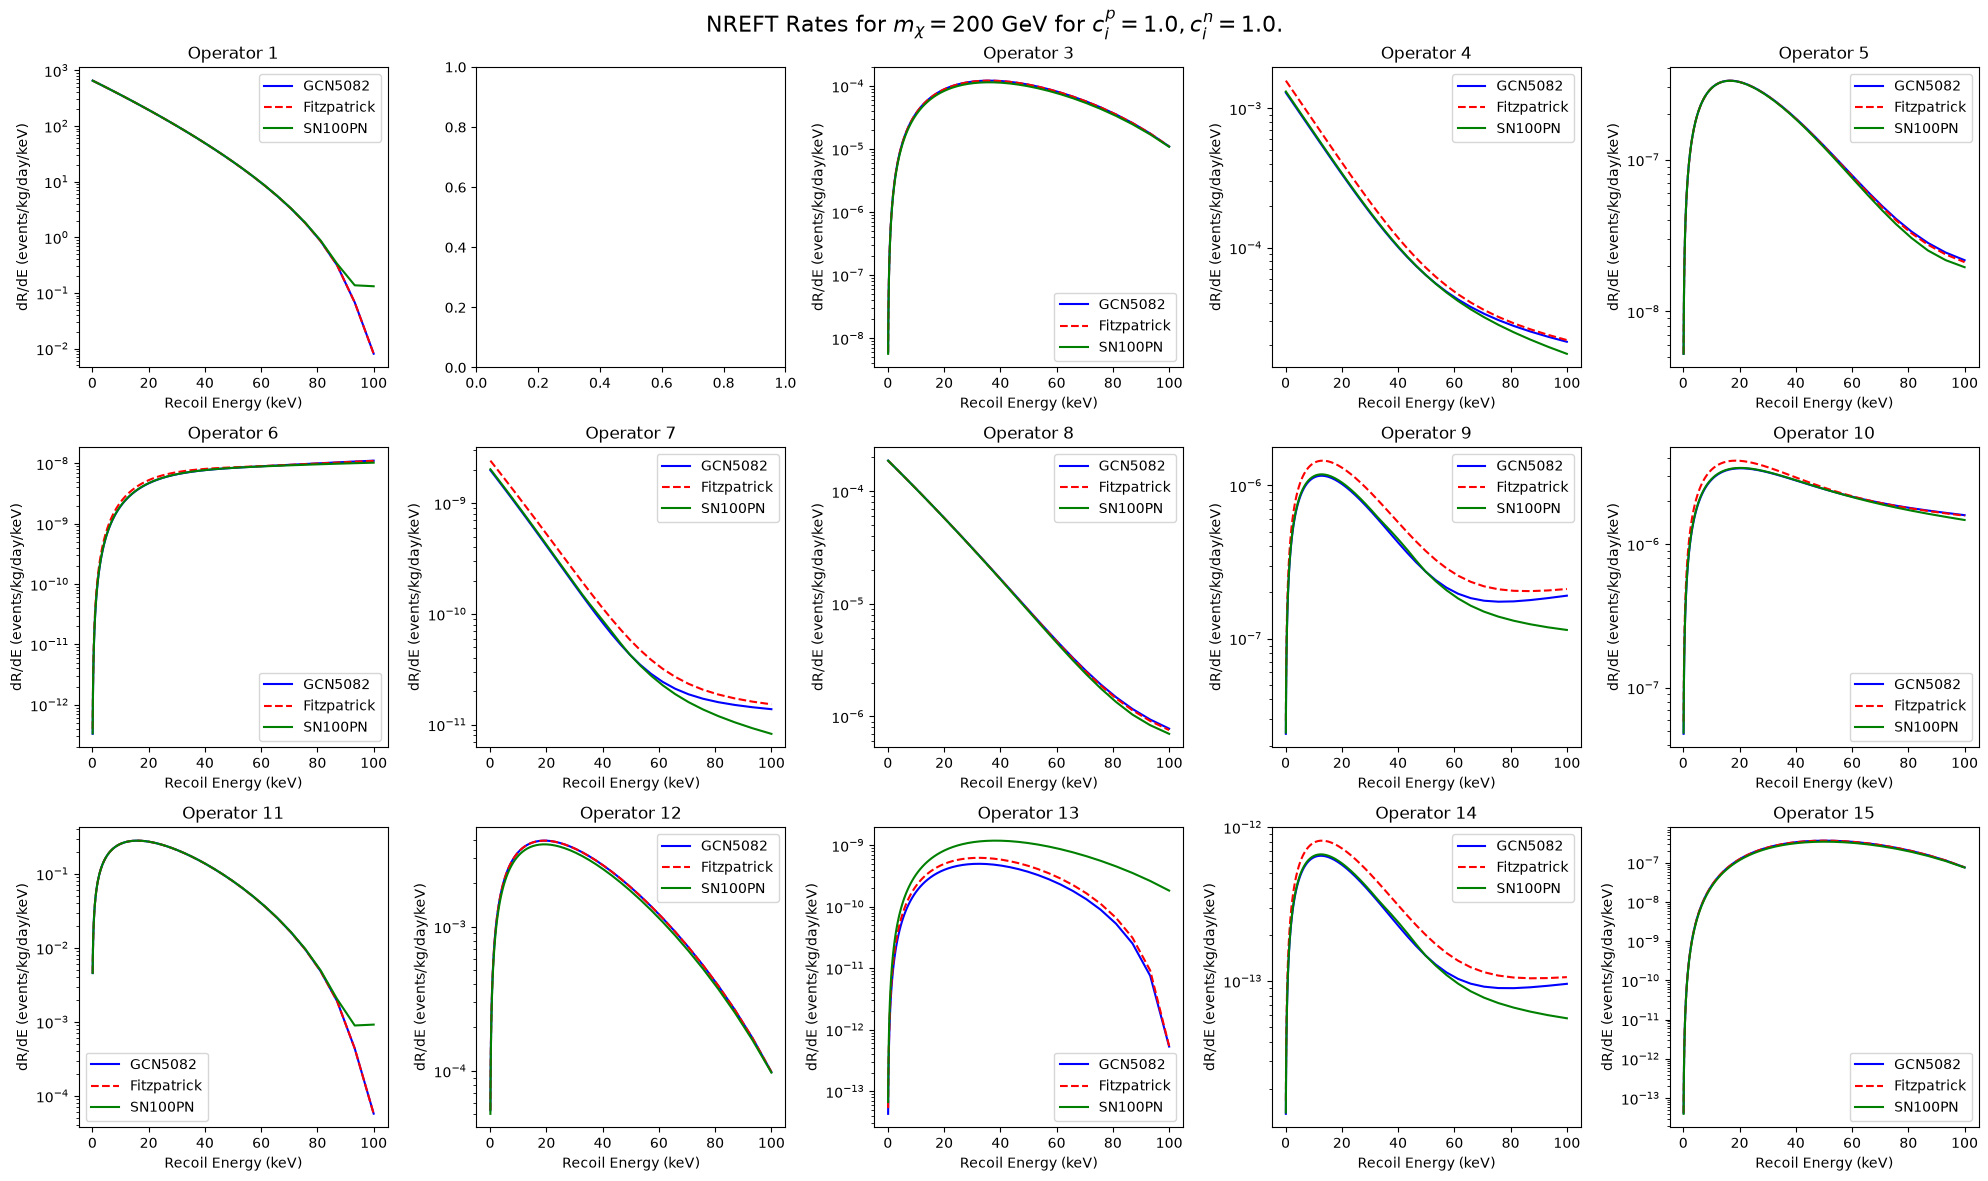

In [4]:
# plot all the NREFT_rates
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()

for i in NREFT_coeffs_list:      
    axes[i-1].plot(energies_NREFT, NREFT_rates[i]['iso_GCN5082'], label='GCN5082', color='blue')
    axes[i-1].plot(energies_NREFT, NREFT_rates[i]['iso_Fitz'], label='Fitzpatrick', color='red', ls='--')
    axes[i-1].plot(energies_NREFT, NREFT_rates[i]['pn_SN100PN'], label='SN100PN', color='green')
    axes[i-1].set_xlabel('Recoil Energy (keV)')
    axes[i-1].set_ylabel('dR/dE (events/kg/day/keV)')
    axes[i-1].set_title(f'Operator {i}')
    axes[i-1].set_yscale('log')
    axes[i-1].legend()

plt.suptitle(f'NREFT Rates for $m_\\chi = {m_chi}$ GeV for $c^p_i = {c_prot},  c^n_i = {c_neut}$.', fontsize=16)
plt.tight_layout()
plt.show()

In [5]:
EFT_coeffs_list = [i for i in range(1, 21)]
m_M = 1 # GeV, mediator mass
nE = 100 # number of energy points
E_min = 0.1 # keV, minimum recoil energy
E_max = 100 # keV, maximum recoil energy
energies_EFT = np.logspace(np.log10(E_min), np.log10(E_max), nE)

In [6]:
EFT_rates = {}
rapidd.read_halo('../lib/halo_table/halo_table_SHM.dat')

for i in EFT_coeffs_list:
    rapidd.reset_coefficients()
    EFT_rates[i] = {}
    for nucl_mod in nuclear_models:
        EFT_rates[i][nucl_mod] = np.zeros(nE)
        for i_E, E in enumerate(energies_EFT):
            rapidd.set_any_N_EFT_coeff(i, m_chi, m_M, nucleon='p', c=1)
            rapidd.set_any_N_EFT_coeff(i, m_chi, m_M, nucleon='n', c=1)
            EFT_rates[i][nucl_mod][i_E] = rapidd.difrate_dER(rhoDM=rhoDM, mDM=m_chi,
                                                             ER=E, model='SHM',
                                                             target=target, basis=nucl_mod)

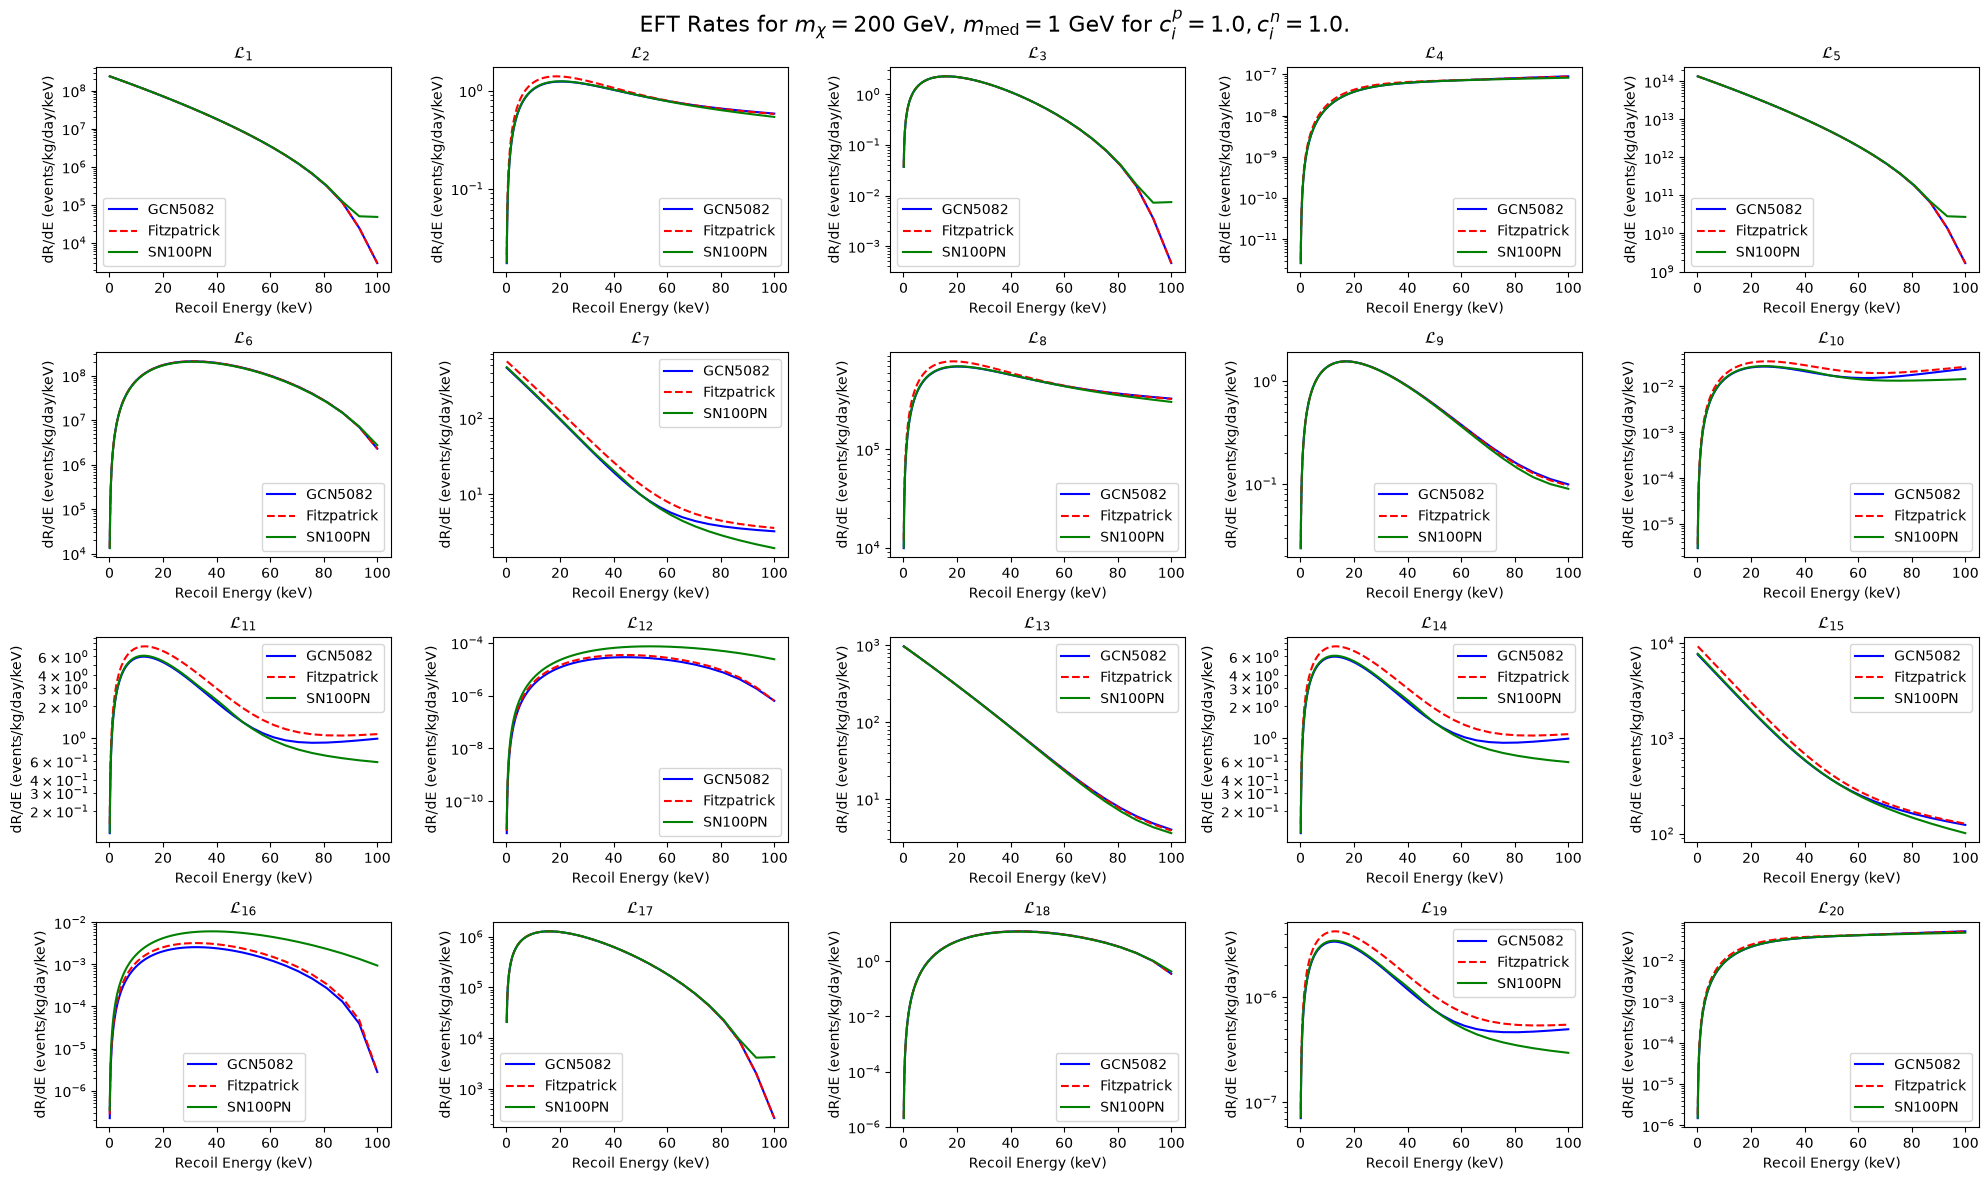

In [7]:
# plot all the EFT_rates
fig, axes = plt.subplots(4, 5, figsize=(20, 12))
axes = axes.flatten()

for i in EFT_coeffs_list:      
    axes[i-1].plot(energies_EFT, EFT_rates[i]['iso_GCN5082']*1000*365, label='GCN5082', color='blue')
    axes[i-1].plot(energies_EFT, EFT_rates[i]['iso_Fitz']*1000*365, label='Fitzpatrick', color='red', ls='--')
    axes[i-1].plot(energies_EFT, EFT_rates[i]['pn_SN100PN']*1000*365, label='SN100PN', color='green')
    axes[i-1].set_xlabel('Recoil Energy (keV)')
    axes[i-1].set_ylabel('dR/dE (events/kg/day/keV)')
    axes[i-1].set_title(f'$\\mathcal{{L}}_{{{i}}}$')
    axes[i-1].set_yscale('log')
    axes[i-1].legend()

plt.suptitle(f'EFT Rates for $m_\\chi = {m_chi}$ GeV, $m_\\text{{med}} = {m_M}$ GeV for $c^p_i = {c_prot},  c^n_i = {c_neut}$.', fontsize=16)
plt.tight_layout()
plt.show()

## 2. Annual modulation
`DDrate_save` with `modulation=True` (see the tutorial). For heavy elastic DM the time average of the modulated
spectra is very close to the spectrum of the annual-average halo (ratio within a few per mille), for inelastic
DM it is not.

In [8]:
import os, tempfile
from rapidd.calc_dRdE import DDrate_save

# maddm_card: halo and quark -> nucleon form factors (MadDM defaults)
card = {'rhoDM': rhoDM, 'vmp': 238., 'vescape': 544., 'vSun_r': 11.1, 'vSun_phi': 12.2, 'vSun_theta': 7.3,
        'vEarth_mod': 29.8,
        'SPu': 0.0153, 'SPd': 0.0191, 'SPs': 0.0447, 'SPg': 1 - 0.0153 - 0.0191 - 0.0447,
        'SNu': 0.0110, 'SNd': 0.0273, 'SNs': 0.0447, 'SNg': 1 - 0.0110 - 0.0273 - 0.0447,
        'VPu': 2.0, 'VPd': 1.0, 'VNu': 1.0, 'VNd': 2.0,
        'AVPu': 0.842, 'AVPd': -0.427, 'AVPs': -0.085, 'AVNu': -0.427, 'AVNd': 0.842, 'AVNs': -0.085,
        'SigPu': 0.84, 'SigPd': -0.23, 'SigPs': -0.046, 'SigNu': -0.23, 'SigNd': 0.84, 'SigNs': -0.046}
alphaq = {'alpha_u': (1e-6, 0., 0., 0.), 'alpha_d': (1e-6, 0., 0., 0.)}  # scalar (SI) DM-quark couplings [GeV^-2]

day_bins = 12  # default of DDrate_save / DDrate_electron_save
out_dir = tempfile.mkdtemp()
DDrate_save(card, alphaq, m_chi, out_dir, modulation=True, day_bins=day_bins, verbose=False)
mod = np.load(os.path.join(out_dir, 'DDrates.npz'))
print(sorted(mod.files))
print(open(os.path.join(out_dir, 'rate_vs_time.dat')).read())

['drde_Ar', 'drde_Ar_avg', 'drde_Ar_bin', 'drde_Ar_year', 'drde_Ge', 'drde_Ge_avg', 'drde_Ge_bin', 'drde_Ge_year', 'drde_Xe', 'drde_Xe_avg', 'drde_Xe_bin', 'drde_Xe_year', 'dt_bin', 'energies', 'rate_Ar_bin', 'rate_Ge_bin', 'rate_Xe_bin', 't_bin']
# t [days since 22-03-2018] dt [days] R_Xe [events/kg/dt] R_Ar [events/kg/dt] R_Ge [events/kg/dt]
1.5218333333E+01 3.0436666667E+01 9.1110239009E+04 1.5200305675E+04 4.4114056032E+04
4.5655000000E+01 3.0436666667E+01 9.0394617072E+04 1.5140404907E+04 4.3842884599E+04
7.6091666667E+01 3.0436666667E+01 9.0176342514E+04 1.5121865935E+04 4.3759784785E+04
1.0652833333E+02 3.0436666667E+01 9.0507500079E+04 1.5149944023E+04 4.3885803177E+04
1.3696500000E+02 3.0436666667E+01 9.1308724912E+04 1.5216696210E+04 4.4188949854E+04
1.6740166667E+02 3.0436666667E+01 9.2381406738E+04 1.5303482758E+04 4.4591011004E+04
1.9783833333E+02 3.0436666667E+01 9.3444895434E+04 1.5386604770E+04 4.4985285065E+04
2.2827500000E+02 3.0436666667E+01 9.4204903213E+04 1.544423

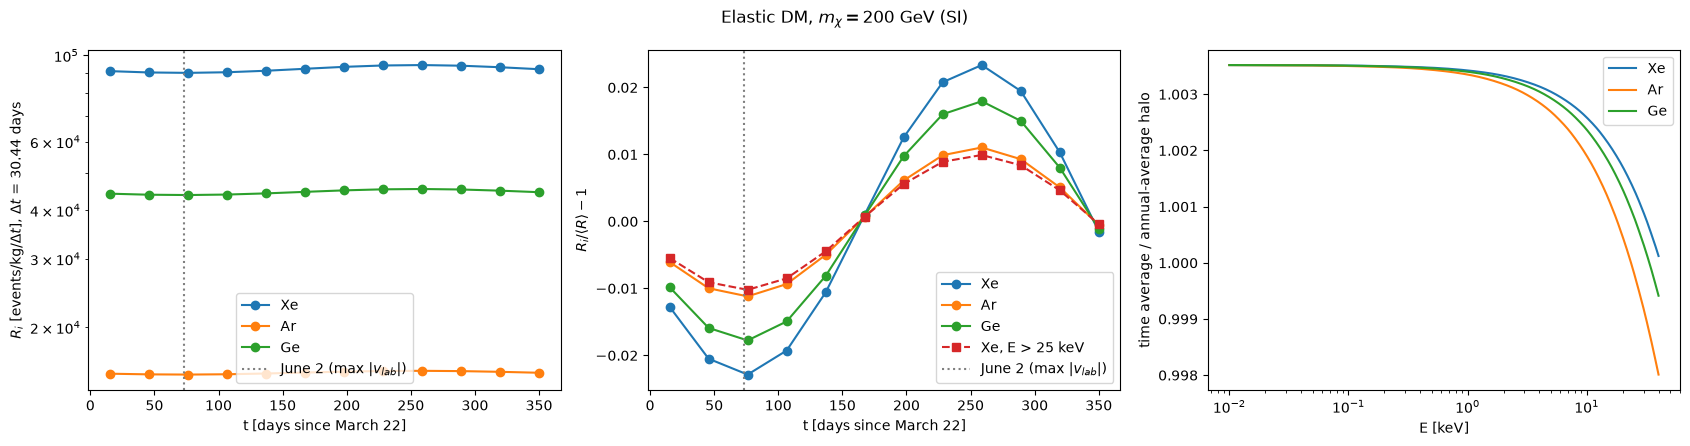

In [9]:
def plot_modulation(mod, names, E, title, extra=None):
    """R_i during the year (events/kg/dt), its relative variation and the ratio between the time
    average of the modulated spectra and the spectrum of the annual-average halo"""
    t, dt = mod['t_bin'], float(mod['dt_bin'])
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for n in names:
        R = mod[f'rate_{n}_bin']
        axes[0].plot(t, R, 'o-', label=n)
        axes[1].plot(t, R / R.mean() - 1, 'o-', label=n)
        ok = mod[f'drde_{n}'] > 0
        axes[2].plot(E[ok], mod[f'drde_{n}_avg'][ok] / mod[f'drde_{n}'][ok], label=n)
    for label, R in (extra or {}).items():
        axes[1].plot(t, R / R.mean() - 1, 's--', label=label)
    for ax in axes[:2]:
        ax.axvline(72.9, color='grey', ls=':', label='June 2 (max $|v_{lab}|$)')
        ax.set_xlabel('t [days since March 22]')
        ax.legend()
    axes[0].set_yscale('log')
    axes[0].set_ylabel(f'$R_i$ [events/kg/$\\Delta t$], $\\Delta t$ = {dt:.2f} days')
    axes[1].set_ylabel(r'$R_i/\langle R\rangle - 1$')
    axes[2].set_xscale('log')
    axes[2].set_xlabel('E [keV]')
    axes[2].set_ylabel('time average / annual-average halo')
    axes[2].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


E = mod['energies']
sel = E >= 25.
R_Xe_25 = mod['drde_Xe_bin'][:, sel] @ rapidd.modulation.trapezoid_weights(E[sel])
plot_modulation(mod, ['Xe', 'Ar', 'Ge'], E, f'Elastic DM, $m_\\chi = {m_chi}$ GeV (SI)',
                extra={'Xe, E > 25 keV': R_Xe_25})

In [10]:
deltas = [0, 100, 200, 300]  # keV
nucl_mod = 'iso_GCN5082'
colors = ['blue', 'orange', 'green', 'red']
rapidd.read_halo('../lib/halo_table/halo_table_SHM.dat')
iDM_rates = {1: {'SHM': {}}}
rapidd.reset_coefficients()
rapidd.set_any_Ncoeff(c_prot, 1, 'p')
rapidd.set_any_Ncoeff(c_neut, 1, 'n')
for delta in deltas:
    iDM_rates[1]['SHM'][delta] = rapidd.difrate_dER(rhoDM, m_chi, energies_NREFT, target=target, basis=nucl_mod,
                                                   delta=delta)

### Inelastic DM: time average of the modulated spectra vs annual-average halo
Same SHM parameters as `halo_table_SHM.dat` (the annual-average halo used above for `iDM_rates`): only the
Earth velocity differs (time-dependent vs fixed March 9 vector). The generic functions of `rapidd.modulation`
work with any spectrum: `modulation_spectra` computes the tables (`modulation_halo_tables`, reused for all the
deltas) and loops over the time bins (`modulated_rates`), the same functions used by `DDrate_save` and
`DDrate_electron_save`.

delta = 0 keV: total rate, time average / annual-average halo = 1.0022, modulation amplitude (max-min)/(max+min) = 0.022
delta = 100 keV: total rate, time average / annual-average halo = 0.9890, modulation amplitude (max-min)/(max+min) = 0.134
delta = 200 keV: total rate, time average / annual-average halo = 0.9948, modulation amplitude (max-min)/(max+min) = 0.494
delta = 300 keV: no events with the annual-average halo (vmin > vesc + v_lab); with the modulation R_i > 0 in 0 of 12 bins (t = [] days), time-averaged total rate 0 events/kg/day


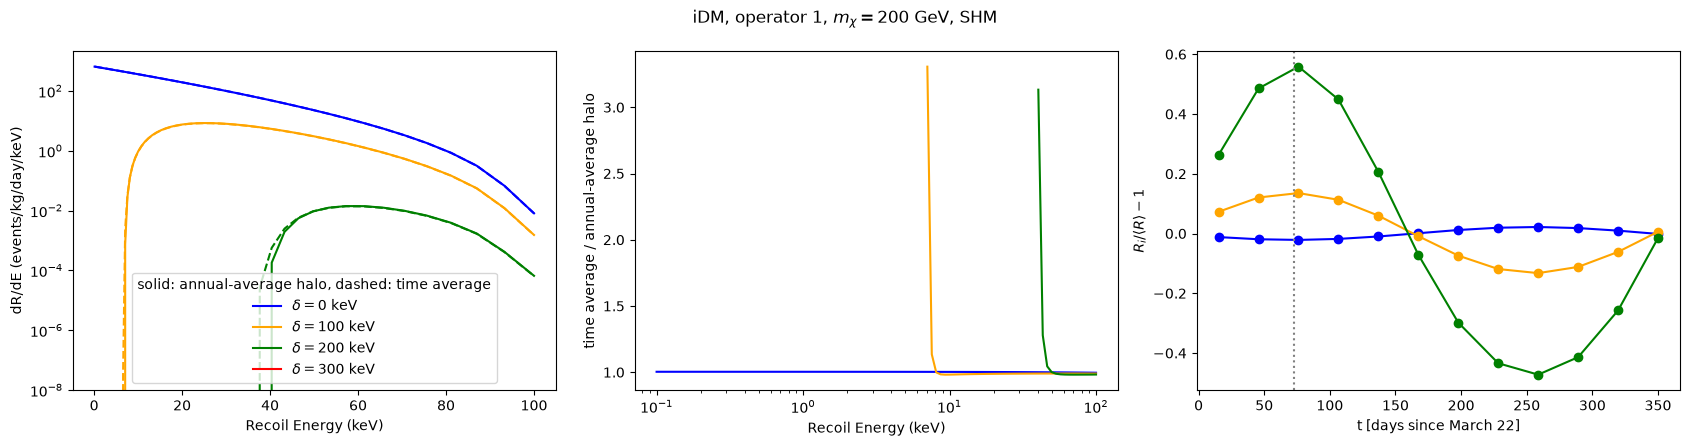

In [11]:
op = 1
rapidd.reset_coefficients()
rapidd.set_any_Ncoeff(c_prot, op, 'p')
rapidd.set_any_Ncoeff(c_neut, op, 'n')
weights = rapidd.modulation.trapezoid_weights(energies_NREFT)
table_dir = os.path.join(out_dir, 'halo_table_modulation_SHM')
iDM_mod = {}
for delta in deltas:
    def spectrum_fn():
        return {'Xe': rapidd.difrate_dER(rhoDM, m_chi, energies_NREFT, target=target, basis=nucl_mod, delta=delta)}
    t_bin, dt, res = rapidd.modulation.modulation_spectra(spectrum_fn, weights, table_dir, day_bins=day_bins,
                                                          verbose=False)  # SHM with the default parameters
    iDM_mod[delta] = res['Xe']

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, delta in enumerate(deltas):
    static = iDM_rates[op]['SHM'][delta]
    avg = iDM_mod[delta]['drde_avg']
    axes[0].plot(energies_NREFT, static, color=colors[k], label=f'$\\delta = {delta}$ keV')
    axes[0].plot(energies_NREFT, avg, color=colors[k], ls='--')
    ok = static > 0
    axes[1].plot(energies_NREFT[ok], avg[ok] / static[ok], color=colors[k])
    R = iDM_mod[delta]['rate_bin']
    if R.max() > 0:
        axes[2].plot(t_bin, R / R.mean() - 1, 'o-', color=colors[k])
    if static @ weights > 0:
        print(f'delta = {delta} keV: total rate, time average / annual-average halo = {(avg @ weights) / (static @ weights):.4f}, '
              f'modulation amplitude (max-min)/(max+min) = {(R.max() - R.min()) / (R.max() + R.min()):.3f}')
    else:
        print(f'delta = {delta} keV: no events with the annual-average halo (vmin > vesc + v_lab); with the modulation '
              f'R_i > 0 in {(R > 0).sum()} of {day_bins} bins (t = {np.round(t_bin[R > 0], 1)} days), '
              f'time-averaged total rate {avg @ weights:.3g} events/kg/day')
axes[0].set_yscale('log'); axes[0].set_ylim(bottom=1e-8)
axes[0].set_xlabel('Recoil Energy (keV)'); axes[0].set_ylabel('dR/dE (events/kg/day/keV)')
axes[0].legend(title='solid: annual-average halo, dashed: time average')
axes[1].set_xscale('log'); axes[1].set_xlabel('Recoil Energy (keV)')
axes[1].set_ylabel('time average / annual-average halo')
axes[2].axvline(72.9, color='grey', ls=':')
axes[2].set_xlabel('t [days since March 22]'); axes[2].set_ylabel(r'$R_i/\langle R\rangle - 1$')
plt.suptitle(f'iDM, operator {op}, $m_\\chi = {m_chi}$ GeV, SHM')
plt.tight_layout()
plt.show()

For inelastic DM the rate comes only from the high-velocity tail of the distribution ($v_{min}$ grows with
$\delta$), which is very sensitive to the lab-frame speed: the modulation is large and the time average of the
modulated spectra can differ a lot from the spectrum of the annual-average halo, especially near the endpoint of
the spectrum (the average of the rate over the year is not the rate at the average velocity, and the March 9
vector is only an approximation of the annual average). For elastic DM the two coincide almost exactly.
The annual-average halo needs a single table instead of `day_bins` tables (and `day_bins` evaluations of the
spectrum), so it is much faster and it is the default; use the modulation when the time dependence matters,
e.g. for inelastic DM near threshold.

## 3. XENONnT limits and wimprates
wimprates (the signal model of the XENONnT limits, e.g. the example of the
[S2-only data release](https://github.com/XENONnT/s2_only_data_release)) is run here with exactly the RAPIDD
velocity distribution: $f(v) = -v\, d\eta_0/dv$ from the annual-average halo table (`halo_model` argument of
`wimprates.rate_wimp`), so that the differences come only from the nuclear physics. The cross sections are
converted with the conventions of `rapidd.alpha_map`: $\sigma_\text{SI} = \mu_N^2 c_1^2/\pi$,
$\sigma_\text{SD} = 3\mu_N^2 c_4^2/(16\pi)$ (the coefficients of `set_any_Ncoeff` are $c_i v^2$).

The XENONnT limits (`tests/data/xenonnt`) are the WIMP search SR0+SR1 ([arXiv:2502.18005](https://arxiv.org/abs/2502.18005),
[wimp_data_release](https://github.com/XENONnT/wimp_data_release)) and the S2-only search SR0+SR1+SR2
([arXiv:2601.11296](https://arxiv.org/abs/2601.11296)); MadDM uses LZ 2024 (SI, SD-n) and PICO-60 (SD-p).
The ratio RAPIDD/wimprates, averaged with the wimprates spectrum over the energy range of each search
(approximately [0.5, 5] keV for S2-only, [3, 60] keV for the WIMP search: the detector efficiency is not
included), gives the factor by which the limit would change if XENONnT used the RAPIDD spectrum:
$\sigma_\text{lim}^\text{RAPIDD} \approx \sigma_\text{lim}^\text{XENONnT} \times \langle\text{wimprates}/\text{RAPIDD}\rangle$.

In [12]:
import warnings
try:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        import wimprates as wr
        import numericalunits as nu
    have_wr = True
except ImportError:
    have_wr = False
    print('wimprates not installed: skipping the comparison')

from rapidd.alpha_map import mneutron, gev_to_pb, pb_to_cm2
from rapidd.core import vev

rapidd.read_halo(rapidd.halo_path)
h = np.loadtxt(rapidd.halo_path, skiprows=1)
v_tab, f_tab = h[:, 0], -h[:, 0] * np.gradient(h[:, 1], h[:, 0])  # lab-frame speed distribution [1/(km/s)]
print(f'normalization of f(v) from the halo table: {np.trapezoid(f_tab, v_tab):.5f}')

if have_wr:
    class RapiddHalo:
        """wimprates halo model with the speed distribution of the RAPIDD halo table"""
        v_esc = 900 * nu.km / nu.s  # only used as an upper bound of the integral
        rho_dm = 0.3 * nu.GeV / nu.c0**2 / nu.cm**3

        def velocity_dist(self, v, t):
            return np.interp(v / (nu.km / nu.s), v_tab, f_tab, left=0., right=0.) / (nu.km / nu.s)

    wr_halo = RapiddHalo()
    wr_unit = 1. / (nu.kg * nu.day * nu.keV)

CASES = {'SI': (1, ('p', 'n'), 'SI'), 'SD-n': (4, ('n',), 'SD_n_central'), 'SD-p': (4, ('p',), 'SD_p_central')}


def rapidd_spectrum(case, m, sigma, E, basis='iso_GCN5082'):
    """RAPIDD dR/dE [events/kg/day/keV] for a DM-nucleon cross section sigma [cm^2]"""
    op, nucleons, _ = CASES[case]
    mu = m * mneutron / (m + mneutron)
    s = sigma / (gev_to_pb * pb_to_cm2)
    c = np.sqrt(np.pi * s) / mu if op == 1 else np.sqrt(16 * np.pi * s / 3) / mu
    rapidd.reset_coefficients()
    for n in nucleons:
        rapidd.set_any_Ncoeff(c * vev**2, op, n)
    return rapidd.difrate_dER(rhoDM, m, E, target='Xe', basis=basis)


def wimprates_spectrum(case, m, sigma, E):
    return wr.rate_wimp(E * nu.keV, m * nu.GeV / nu.c0**2, sigma * nu.cm**2, interaction=CASES[case][2],
                        halo_model=wr_halo) / wr_unit

normalization of f(v) from the halo table: 0.99991


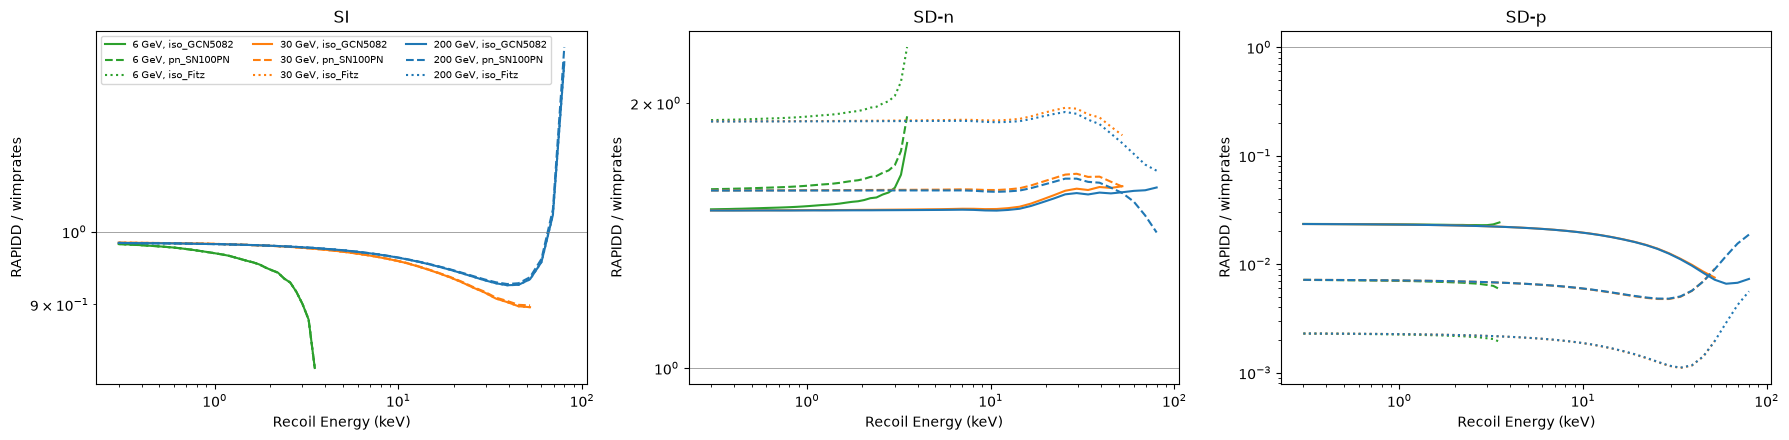

In [13]:
if have_wr:
    bases = {'iso_GCN5082': '-', 'pn_SN100PN': '--', 'iso_Fitz': ':'}
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, (case, sigma) in zip(axes, (('SI', 1e-45), ('SD-n', 1e-40), ('SD-p', 1e-40))):
        for m, color in ((6., 'tab:green'), (30., 'tab:orange'), (200., 'tab:blue')):
            E = np.geomspace(0.3, 6. if m < 10 else 80., 40)
            y_wr = wimprates_spectrum(case, m, sigma, E)
            ok = y_wr > 1e-4 * y_wr.max()
            for b, ls in bases.items():
                ax.plot(E[ok], rapidd_spectrum(case, m, sigma, E, b)[ok] / y_wr[ok], color=color, ls=ls,
                        label=f'{m:g} GeV, {b}')
        ax.axhline(1, color='grey', lw=0.5)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Recoil Energy (keV)')
        ax.set_ylabel('RAPIDD / wimprates')
        ax.set_title(case)
    axes[0].legend(fontsize=7, ncol=3)
    plt.tight_layout()
    plt.show()

- **SI**: RAPIDD / wimprates = 0.98 at threshold, decreasing to ~0.9 at the end of the spectrum (shell-model vs
  Helm form factor), the same for the three nuclear models. The XENONnT and LZ SI limits can be used with the
  RAPIDD cross section within ~5% (RAPIDD limits 3-6% weaker, below).
- **SD-n**: RAPIDD is 1.5-1.6 (GCN5082, SN100PN) and 1.9-2.0 (Fitzpatrick et al.) times wimprates: the nuclear
  responses of RAPIDD only include one-body currents, while wimprates (Klos et al., "central" values) includes
  the two-body currents, which reduce the SD-n structure function of Xenon. The limits on $\sigma_\text{SD-n}$
  computed with RAPIDD would be correspondingly stronger.
- **SD-p**: RAPIDD is 40-500 times below wimprates (and the three nuclear models differ by a factor 10): for
  Xenon the proton spin is tiny and the coupling to protons comes mostly from the two-body currents, which are
  missing in RAPIDD. The Xenon SD-p limits cannot be used with the RAPIDD spectra; MadDM uses PICO-60 (Fluorine).

SI WIMP SR0+SR1: <wimprates/RAPIDD> = 1.040-1.050 for m = 10-10000 GeV
SI S2-only: <wimprates/RAPIDD> = 1.026-1.063 for m = 3-12 GeV


SD-n WIMP SR0+SR1: <wimprates/RAPIDD> = 0.650-0.657 for m = 10-10000 GeV


SD-n S2-only: <wimprates/RAPIDD> = 0.639-0.659 for m = 3-12 GeV


SD-p WIMP SR0+SR1: <wimprates/RAPIDD> = 45.386-63.434 for m = 10-10000 GeV


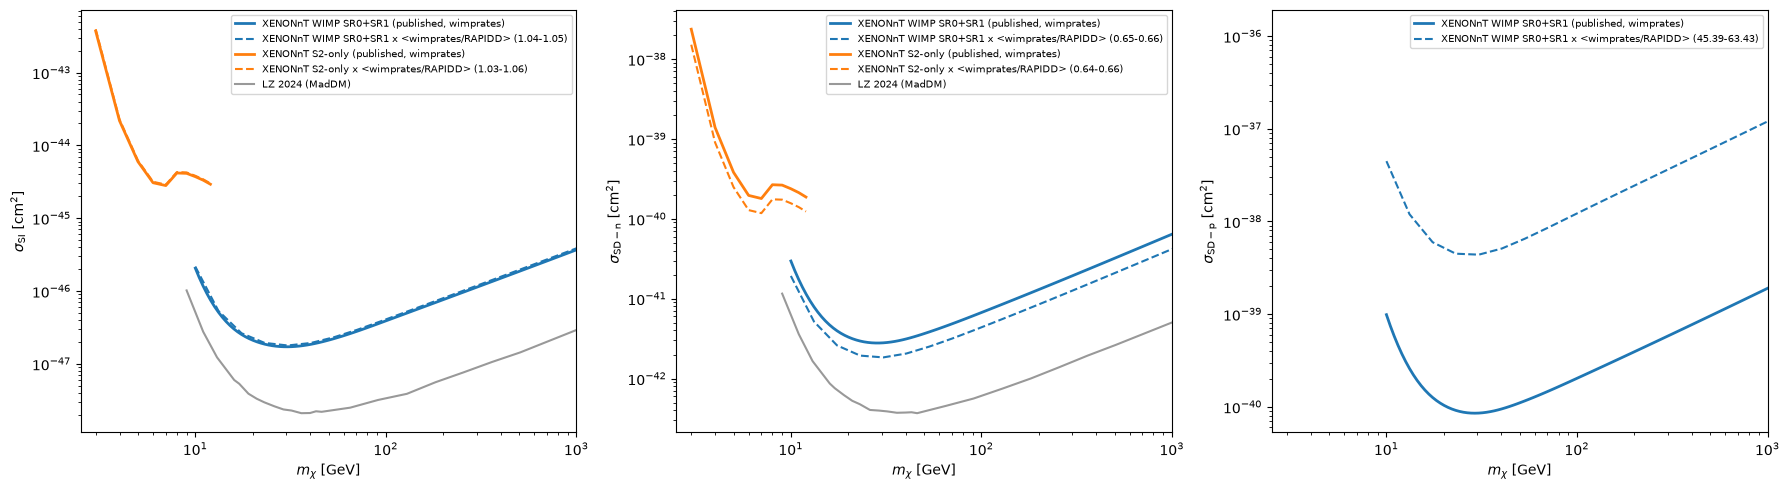

In [14]:
import pandas as pd

nt_dir = '../tests/data/xenonnt/'
nt = {('SI', 'WIMP SR0+SR1'): (pd.read_csv(nt_dir + 'xenonnt_2025_si_wimp.csv'), 'mass', 'upper_limit', (3., 60.)),
      ('SD-n', 'WIMP SR0+SR1'): (pd.read_csv(nt_dir + 'xenonnt_2025_sd_neutron_wimp.csv'), 'mass', 'upper_limit', (3., 60.)),
      ('SD-p', 'WIMP SR0+SR1'): (pd.read_csv(nt_dir + 'xenonnt_2025_sd_proton_wimp.csv'), 'mass', 'upper_limit', (3., 60.)),
      ('SI', 'S2-only'): (pd.read_csv(nt_dir + 'XENONnT_SR012_s2_only_wimp_si_after_pcl_limit.csv'), 'mass_gev', 'limit_cm2', (0.5, 5.)),
      ('SD-n', 'S2-only'): (pd.read_csv(nt_dir + 'XENONnT_SR012_s2_only_wimp_sdn_after_pcl_limit.csv'), 'mass_gev', 'limit_cm2', (0.5, 5.))}
lz = {'SI': np.loadtxt('../lib/experiments/lz2024/LZ2024_SI.dat'), 'SD-n': np.loadtxt('../lib/experiments/lz2024/LZ2024_SDn.dat')}


def recast_factor(case, m, window):
    """<wimprates/RAPIDD> over the energy window, weighted with the wimprates spectrum"""
    E = np.geomspace(*window, 60)
    y_wr = wimprates_spectrum(case, m, 1e-45, E)
    y_r = rapidd_spectrum(case, m, 1e-45, E)
    if np.trapezoid(y_r, E) <= 0:
        return np.nan
    return np.trapezoid(y_wr, E) / np.trapezoid(y_r, E)


if have_wr:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, case in zip(axes, ('SI', 'SD-n', 'SD-p')):
        for (c, search), (df, mcol, lcol, window) in nt.items():
            if c != case:
                continue
            m = df[mcol].values
            sel = m[::max(1, len(m) // 15)]
            fac = np.array([recast_factor(case, mm, window) for mm in sel])
            l, = ax.plot(m, df[lcol], lw=2, label=f'XENONnT {search} (published, wimprates)')
            ax.plot(sel, np.interp(sel, m, df[lcol]) * fac, ls='--', color=l.get_color(),
                    label=f'XENONnT {search} x <wimprates/RAPIDD> ({np.nanmin(fac):.2f}-{np.nanmax(fac):.2f})')
            print(f'{case} {search}: <wimprates/RAPIDD> = {np.nanmin(fac):.3f}-{np.nanmax(fac):.3f} '
                  f'for m = {sel.min():g}-{sel.max():g} GeV')
        if case in lz:
            ax.plot(lz[case][:, 0], lz[case][:, 1], color='k', alpha=0.4, label='LZ 2024 (MadDM)')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(r'$m_\chi$ [GeV]')
        ax.set_ylabel(rf'$\sigma_\mathrm{{{case}}}$ [cm$^2$]')
        ax.set_xlim(2.5, 1e3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()
rapidd.reset_coefficients()

The dashed curves are the XENONnT limits rescaled to the RAPIDD spectra (approximately: the detector efficiency
inside the energy window is ignored). For SI the correction is 3-6%; for SD-n the RAPIDD limits would be
stronger by a factor ~1.5 (0.64-0.66 times the published ones), because of the missing two-body currents; for SD-p the factor is so large that the comparison is
meaningless (two-body currents missing in RAPIDD).